CSV Data:
    OrderID Product     Category  Quantity  Price Customer
0      101  Laptop  Electronics       2.0  50000        A
1      102  Mobile  Electronics       3.0  15000        B
2      103  Tablet  Electronics       1.0  20000        C
3      104  Laptop  Electronics       2.0  50000        A
4      105  Mobile  Electronics       NaN  15000        D

Excel Data:
    OrderID Product     Category  Quantity  Price Customer
0      101  Laptop  Electronics       2.0  50000        A
1      102  Mobile  Electronics       3.0  15000        B
2      103  Tablet  Electronics       1.0  20000        C
3      104  Laptop  Electronics       2.0  50000        A
4      105  Mobile  Electronics       NaN  15000        D

JSON Data:
    OrderID Product     Category  Quantity  Price Customer
0      101  Laptop  Electronics       2.0  50000        A
1      102  Mobile  Electronics       3.0  15000        B
2      103  Tablet  Electronics       1.0  20000        C
3      104  Laptop  Electronics   

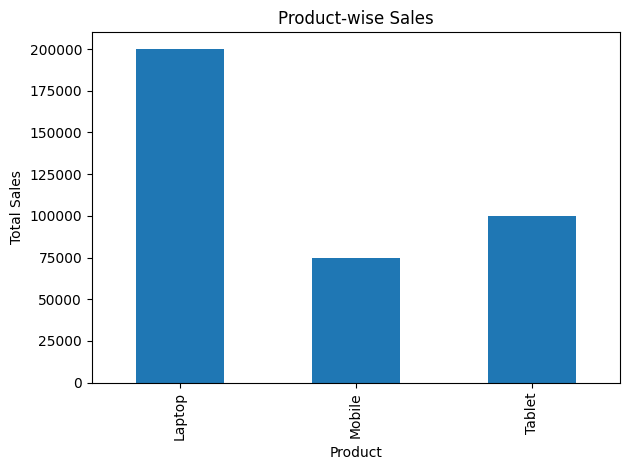

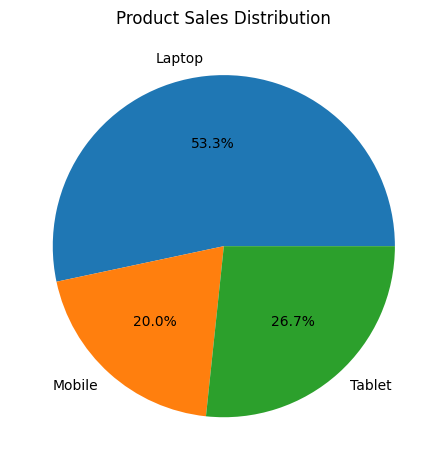

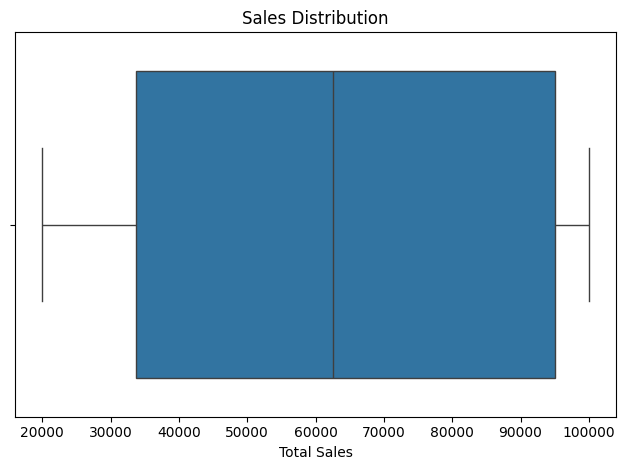


Cleaned dataset saved successfully.


In [3]:
#7.sales_data_analysis
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create sample sales dataset
data = {
    "OrderID": [101, 102, 103, 104, 105, 106],
    "Product": ["Laptop", "Mobile", "Tablet", "Laptop",
                "Mobile", "Tablet"],
    "Category": ["Electronics", "Electronics", "Electronics",
                 "Electronics", "Electronics", "Electronics"],
    "Quantity": [2, 3, 1, 2, None, 4],
    "Price": [50000, 15000, 20000, 50000, 15000, 20000],
    "Customer": ["A", "B", "C", "A", "D", "E"]
}

df = pd.DataFrame(data)

# 2. Save data in CSV, Excel and JSON formats
df.to_csv("sales.csv", index=False)
df.to_excel("sales.xlsx", index=False)
df.to_json("sales.json", orient="records", indent=4)

# 3. Load data from different formats
csv_data = pd.read_csv("sales.csv")
excel_data = pd.read_excel("sales.xlsx")
json_data = pd.read_json("sales.json")

print("CSV Data:\n", csv_data.head())
print("\nExcel Data:\n", excel_data.head())
print("\nJSON Data:\n", json_data.head())

# 4. Explore data quality
print("\nMissing Values:\n", csv_data.isnull().sum())
print("\nDuplicate Rows:", csv_data.duplicated().sum())
print("\nDataset Information:")
csv_data.info()

# 5. Combine datasets into one DataFrame
sales = pd.concat(
    [csv_data, excel_data, json_data],
    ignore_index=True
)

# 6. Clean data
sales = sales.drop_duplicates()
sales["Quantity"] = sales["Quantity"].fillna(
    sales["Quantity"].median()
)
sales["Product"] = sales["Product"].str.strip().str.title()
sales["Customer"] = sales["Customer"].str.strip()

# 7. Transform data
sales["TotalSales"] = sales["Quantity"] * sales["Price"]

print("\nCleaned Data:\n", sales.head())

# 8. Descriptive statistics
print("\nDescriptive Statistics:")
print(sales[["Quantity", "Price", "TotalSales"]].describe())

print("\nTotal Sales:", sales["TotalSales"].sum())
print("Average Order Value:", round(sales["TotalSales"].mean(), 2))

# 9. Product-wise sales
product_sales = sales.groupby("Product")["TotalSales"].sum()
print("\nProduct-wise Sales:\n", product_sales)

# 10. Bar chart
product_sales.plot(kind="bar", title="Product-wise Sales",
                   ylabel="Total Sales", xlabel="Product")
plt.tight_layout()
plt.show()

# 11. Pie chart
product_sales.plot(kind="pie", autopct="%1.1f%%",
                   title="Product Sales Distribution")
plt.ylabel("")
plt.tight_layout()
plt.show()

# 12. Box plot
sns.boxplot(x=sales["TotalSales"])
plt.title("Sales Distribution")
plt.xlabel("Total Sales")
plt.tight_layout()
plt.show()

# 13. Save cleaned dataset
sales.to_csv("cleaned_sales.csv", index=False)
print("\nCleaned dataset saved successfully.")

In [2]:
%pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]
Note: you may need to restart the kernel to use updated packages.
